Importing the libraries

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn import metrics

Data Collection and processing

In [10]:
# Loading the csv data to a pandas Dataframe
Gold = pd.read_csv('/content/gold_price_data.csv')

print first 5 row using head function

In [11]:
Gold.head()

,Date,SPX,GLD,USO,SLV,EUR/USD
0,01/02/2008,1447.160034,84.860001,78.470001,15.180,1.471692
1,01/03/2008,1447.160034,85.570000,78.370003,15.285,1.474491
2,01/04/2008,1411.630005,85.129997,77.309998,15.167,1.475492
3,01/07/2008,1416.180054,84.769997,75.500000,15.053,1.468299
4,01/08/2008,1390.189941,86.779999,76.059998,15.590,1.557099


In [12]:
Gold.shape

(2290, 6)

Getting some basic information about the data

In [13]:
Gold.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2290 entries, 0 to 2289
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Date     2290 non-null   object 
 1   SPX      2290 non-null   float64
 2   GLD      2290 non-null   float64
 3   USO      2290 non-null   float64
 4   SLV      2290 non-null   float64
 5   EUR/USD  2290 non-null   float64
dtypes: float64(5), object(1)
memory usage: 107.5+ KB


Checking null value

In [18]:
Gold.isnull().sum()

,0
Date,0
SPX,0
GLD,0
USO,0
SLV,0
EUR/USD,0


Getting stastical measure of the data

In [19]:
Gold.describe()

,SPX,GLD,USO,SLV,EUR/USD
count,2290.000000,2290.000000,2290.000000,2290.000000,2290.000000
mean,1654.315776,122.732875,31.842221,20.084997,1.283653
std,519.111540,23.283346,19.523517,7.092566,0.131547
min,676.530029,70.000000,7.960000,8.850000,1.039047
25%,1239.874969,109.725000,14.380000,15.570000,1.171313
50%,1551.434998,120.580002,33.869999,17.268500,1.303297
75%,2073.010070,132.840004,37.827501,22.882500,1.369971
max,2872.870117,184.589996,117.480003,47.259998,1.598798


find the correlation
1. Positive
2. Nagative

In [26]:
Correlation = Gold.select_dtypes(include=[np.number]).corr()

Constructing head map to understand the correlation

<Axes: >

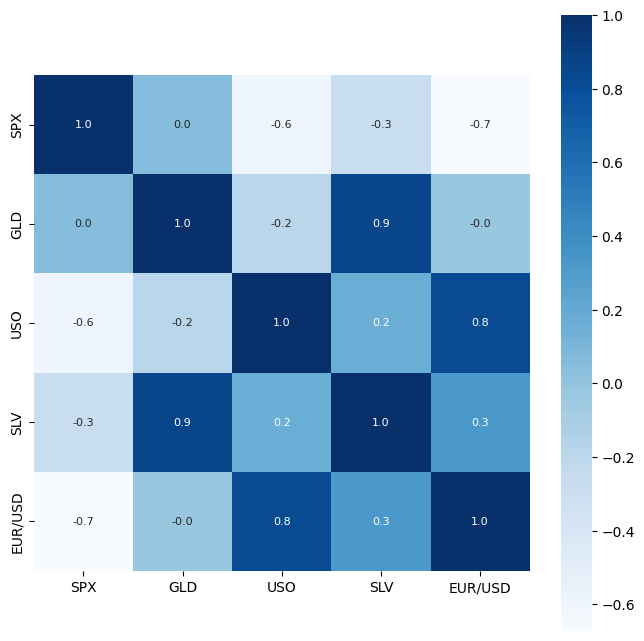

In [27]:
plt.figure(figsize=(8,8))
sns.heatmap(Correlation, cbar=True, square=True, fmt= '.1f', annot=True, annot_kws={'size':8}, cmap='Blues')

Correlation value of Gold

In [30]:
print(Correlation['GLD'])

SPX        0.049345
GLD        1.000000
USO       -0.186360
SLV        0.866632
EUR/USD   -0.024375
Name: GLD, dtype: float64


Check the distribution of gold price

/tmp/ipykernel_20449/433917422.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(Gold['GLD'], color='blue')


<Axes: xlabel='GLD', ylabel='Density'>

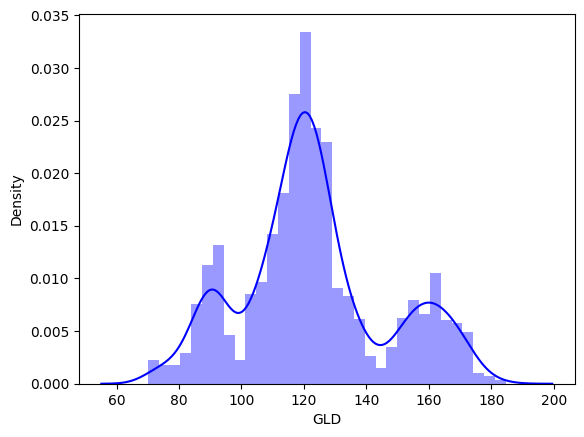

In [31]:
sns.distplot(Gold['GLD'], color='blue')

Splitting the features and Target

In [32]:
X = Gold.drop(['Date','GLD'], axis=1)
Y = Gold['GLD']

In [33]:
X

,SPX,USO,SLV,EUR/USD
0,1447.160034,78.470001,15.1800,1.471692
1,1447.160034,78.370003,15.2850,1.474491
2,1411.630005,77.309998,15.1670,1.475492
3,1416.180054,75.500000,15.0530,1.468299
4,1390.189941,76.059998,15.5900,1.557099
...,...,...,...,...
2285,2671.919922,14.060000,15.5100,1.186789
2286,2697.790039,14.370000,15.5300,1.184722
2287,2723.070068,14.410000,15.7400,1.191753
2288,2730.129883,14.380000,15.5600,1.193118


In [34]:
X_train, X_test, Y_train, Y_test = train_test_split(X,Y, test_size=0.2, random_state=2)

Model Training

In [35]:
model = RandomForestRegressor(n_estimators=100)

Trin the model

In [36]:
model.fit(X_train, Y_train)

RandomForestRegressor()

Model Evaluation

In [37]:
# Prediction on Test data
test_data_prediction  = model.predict(X_test)

In [38]:
print(test_data_prediction)

[168.61559938  81.84959995 115.87970047 127.83480062 120.56390097
 154.77549788 150.46909857 126.12150001 117.60159885 126.08140046
 116.68080102 172.43800033 141.63939838 168.02149825 115.28990042
 117.45210026 139.07030332 170.00570047 159.4455027  159.49279912
 154.96100074 125.14450008 175.72299949 157.4692029  125.09530057
  93.81029961  77.12940018 120.61040026 119.07409944 167.5705997
  88.0837005  125.41689996  91.27450083 117.52350004 121.16279897
 136.2857012  115.32040138 115.39970113 149.11039981 107.33680081
 104.3099023   87.27639801 126.52190054 117.87820024 152.18849872
 119.44060011 108.45409979 108.12609824  93.14990081 127.0373982
  75.08260045 113.73339908 121.50099996 111.30929903 119.00579899
 120.95489962 159.31679911 168.8542012  146.93889706  85.73449846
  94.40000035  86.86709898  90.49530017 118.84620044 126.4415006
 127.52950001 169.49509983 122.2829995  117.31819907  98.52040014
 167.40350058 142.93189794 131.88530242 121.195402   121.42429936
 119.65110045

R Squared error

In [39]:
error_score = metrics.r2_score(Y_test, test_data_prediction)
print("R squared error : ", error_score)

R squared error :  0.9889564530351144


Compare the actual values and predicted value in plot

In [40]:
Y_test = list(Y_test)

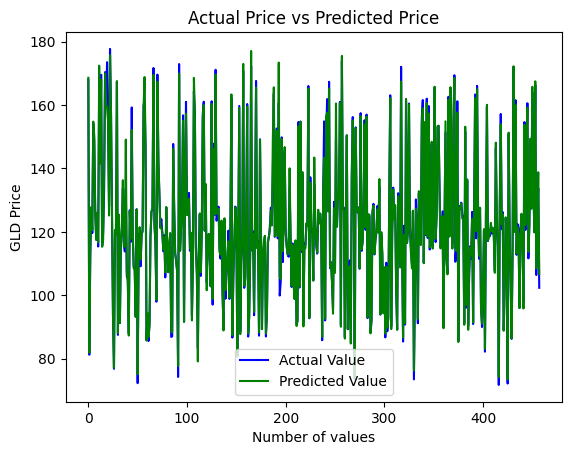

In [41]:
plt.plot(Y_test, color='blue', label='Actual Value')
plt.plot(test_data_prediction, color='green', label='Predicted Value')
plt.title('Actual Price vs Predicted Price')
plt.xlabel('Number of values')
plt.ylabel('GLD Price')
plt.legend()
plt.show()

### Making Predictions with the Saved Model
Here is how you can load your saved model and use it to predict the Gold Price (`GLD`) for any new market indicators.

In [54]:
import joblib
import pandas as pd

# 1. Load the saved model
loaded_model = joblib.load('gld_rf_model.pkl')

# 2. Define new input values for the features in the exact same order:
# [SPX, USO, SLV, EUR/USD]
new_data = pd.DataFrame({
    'SPX': [7201.0898],
    'USO': [135.4300],
    'SLV': [36.8400],
    'EUR/USD': [1.0949]
})

# 3. Predict the GLD price
predicted_gld = loaded_model.predict(new_data)

print(f"For the input features:\n{new_data.to_string(index=False)}")
print(f"\nPredicted GLD Price: ${predicted_gld[0]:.2f}")

For the input features:
      SPX    USO   SLV  EUR/USD
7201.0898 135.43 36.84   1.0949

Predicted GLD Price: $167.03


In [53]:
!pip install -q yfinance
import yfinance as yf

tickers = {
    'S&P 500 (SPX)': '^GSPC',
    'US Oil Fund (USO)': 'USO',
    'Silver Trust (SLV)': 'SLV',
    'EUR/USD': 'EURUSD=X'
}

print("Fetching live market values...\n")
for name, symbol in tickers.items():
    ticker = yf.Ticker(symbol)
    live_price = ticker.history(period='1d')['Close'].iloc[-1]
    print(f"{name}: {live_price:.4f}")

Fetching live market values...

S&P 500 (SPX): 7201.0898
US Oil Fund (USO): 135.4300
Silver Trust (SLV): 36.8400
EUR/USD: 1.0949


In [51]:
accuracy_score = model.score(X_test, Y_test)
print("Accuracy:",accuracy_score)

Accuracy: 0.9889564530351144


In [52]:
accuracy_score = model.score(X_train, Y_train)
print("Accuracy:",accuracy_score)

Accuracy: 0.9984197087428268
